In [ ]:
!pip install adjustText

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [ ]:
# Evaluated models
bert_models = [
    "distilbert-base-spanish-uncased",
    "roberta-large-bne",
    "mdeberta-v3-base"
    # "longformer-base-4096"
]
open_source_llms = [
    "llama-3.1-8b",
    "gpt-oss-20b",
    "deepseek-chat"
]
proprietary_llms = [
    "gpt-5.2",
    "gpt-5-mini",
    "claude-sonnet-4-6",
    "claude-haiku-4.5",
    "gemini-3.1-pro-preview",
    "gemini-3-flash-preview"
]

llm_models = open_source_llms + proprietary_llms
models = bert_models + llm_models

tasks = ["anx", "dep", "ed", "multi"]

# Read metrics tables

In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base = "/content/drive/MyDrive/tfg/corpusMentalRiskES/resultados/"
CACHE_DIR = base + "metricas"

# Read data and tables generated in 5_1_metrics.ipynb
data = pd.read_parquet(f"{CACHE_DIR}/all_predictions.parquet")
metricas_anx = pd.read_csv(f"{CACHE_DIR}/metricas_anx.csv", index_col="model")
metricas_dep = pd.read_csv(f"{CACHE_DIR}/metricas_dep.csv", index_col="model")
metricas_ed = pd.read_csv(f"{CACHE_DIR}/metricas_ed.csv", index_col="model")
metricas_multi = pd.read_csv(f"{CACHE_DIR}/metricas_multi.csv", index_col="model")

In [ ]:
data.tail()

,sample_id,user_id,model,task,y_true,y_pred
4811,subject68_ed,subject68,gemini-3-flash-preview,multi,3,3
4812,subject8_ed,subject8,gemini-3-flash-preview,multi,3,3
4813,subject83_ed,subject83,gemini-3-flash-preview,multi,0,2
4814,subject95_ed,subject95,gemini-3-flash-preview,multi,3,3
4815,subject97_ed,subject97,gemini-3-flash-preview,multi,3,3


# Cost-performance chart

In [ ]:
#========================================
# BERT cost
#========================================

# total time (fine-tuning + inference) BERT models in seconds:
tiempo_bert = {
    "distilbert-base-spanish-uncased": (77.68, 103.1, 75.78, 105.47),
    "roberta-large-bne": (694.06, 652.46, 371.18, 782.1),
    "mdeberta-v3-base": (180.84, 321.9, 866.52, 637.3),
    # "longformer-base-4096": (623.34, 730.82, 423.73, 5162.41)
}

# BERT cost ≈ inference_time × GPU price/hour
coste_gpu_hora = 0.41  # USD/h

coste_bert = {
    modelo: tuple((segundos / 3600) * coste_gpu_hora for segundos in valores)
    for modelo, valores in tiempo_bert.items()
}

#========================================
# LLM cost (USD)
#========================================

# Obtained directly from the APIs
coste_llm = {
    "llama-3.1-8b": (0.003105, 0.00264, 0.001815, 0.00894),
    "gpt-oss-20b": (0.01716, 0.014655, 0.010185, 0.0495),
    "deepseek-chat": (0.0165, 0.0135, 0.0105, 0.048),
    "claude-sonnet-4-6": (0.2745, 0.231, 0.1605, 0.7815),
    "claude-haiku-4.5": (0.168, 0.141, 0.108, 0.465),
    "gpt-5.2": (0.0975, 0.084, 0.057, 0.282),
    "gpt-5-mini": (0.0765, 0.072, 0.066, 0.213),
    "gemini-3.1-pro-preview": (0.132, 0.111, 0.0765, 0.378),
    "gemini-3-flash-preview": (0.057, 0.066, 0.036, 0.171)
}

In [ ]:
def plot_eficacia_coste(metrics_df, task):
    """
    Generates a Cost vs Macro F1 chart and visually identifies
    the Pareto frontier.

    X axis: total cost (lower = better)
    Y axis: macro F1 (higher = better)

    The models on the Pareto frontier are those
    that are not dominated by another model that is simultaneously
    cheaper and more accurate.
    """

    task_idx = {
        "anx": 0,
        "dep": 1,
        "ed": 2,
        "multi": 3
    }[task]

    # =========================================================
    # Unify costs
    # =========================================================

    all_costs = {**coste_bert, **coste_llm}

    # =========================================================
    # Visual configuration
    # =========================================================

    model_styles = {
        "bert": {
            "models": bert_models,
            "color": "blue",
            "marker": "o",
            "label": "BERT"
        },
        "open_llm": {
            "models": open_source_llms,
            "color": "green",
            "marker": "o",
            "label": "Open-source LLMs"
        },
        "prop_llm": {
            "models": proprietary_llms,
            "color": "green",
            "marker": "^",
            "label": "Proprietary LLMs"
        }
    }

    # =========================================================
    # Save all points for Pareto
    # =========================================================

    points = []

    for model in metrics_df.index:

        if model not in all_costs:
            continue

        cost = all_costs[model][task_idx]
        f1_value = metrics_df.loc[model, "f1_macro"]

        points.append({
            "model": model,
            "cost": cost,
            "f1": f1_value
        })

    # =========================================================
    # Calculate Pareto frontier
    # =========================================================

    pareto_models = []

    for p in points:
        dominated = False

        for q in points:

            if p["model"] == q["model"]:
                continue

            # q dominates p if:
            # costs less or equal
            # and has better or equal F1
            # and strict improvement in at least one dimension

            if (
                q["cost"] <= p["cost"]
                and q["f1"] >= p["f1"]
                and (
                    q["cost"] < p["cost"]
                    or q["f1"] > p["f1"]
                )
            ):
                dominated = True
                break

        if not dominated:
            pareto_models.append(p)

    # Sort frontier to draw line
    pareto_models = sorted(
        pareto_models,
        key=lambda x: x["cost"]
    )

    # =========================================================
    # Main plot
    # =========================================================

    plt.figure(figsize=(10, 7))

    texts = []

    for group in model_styles.values():

        x_cost = []
        y_f1 = []
        labels = []

        for model in group["models"]:
            if model not in metrics_df.index:
                continue

            cost = all_costs[model][task_idx]
            f1_value = metrics_df.loc[model, "f1_macro"]

            x_cost.append(cost)
            y_f1.append(f1_value)
            labels.append(model)

        plt.scatter(
            x_cost,
            y_f1,
            color=group["color"],
            marker=group["marker"],
            s=180,
            alpha=0.8,
            label=group["label"]
        )

        for x, y, label in zip(x_cost, y_f1, labels):
            texts.append(
                plt.text(
                    x,
                    y,
                    label,
                    fontsize=12
                )
            )

    # =========================================================
    # Highlight Pareto frontier
    # =========================================================

    pareto_x = [p["cost"] for p in pareto_models]
    pareto_y = [p["f1"] for p in pareto_models]

    plt.plot(
        pareto_x,
        pareto_y,
        linestyle="--",
        color="red",
        alpha=0.6,
        linewidth=2,
        label="Pareto frontier"
    )

    # highlight Pareto points
    plt.scatter(
        pareto_x,
        pareto_y,
        s=300,
        facecolors="none",
        edgecolors="black",
        linewidths=2
    )

    # =========================================================
    # Automatically adjust labels
    # =========================================================
    adjust_text(
        texts,
        arrowprops=dict(
            arrowstyle="-",
            color="gray",
            lw=0.5
        )
    )

    # =========================================================
    # End
    # =========================================================

    plt.xlabel("Cost (USD)", fontsize=14)
    plt.ylabel("Macro F1-score", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    # plt.title(f"Eficacia vs Coste - {task}")

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

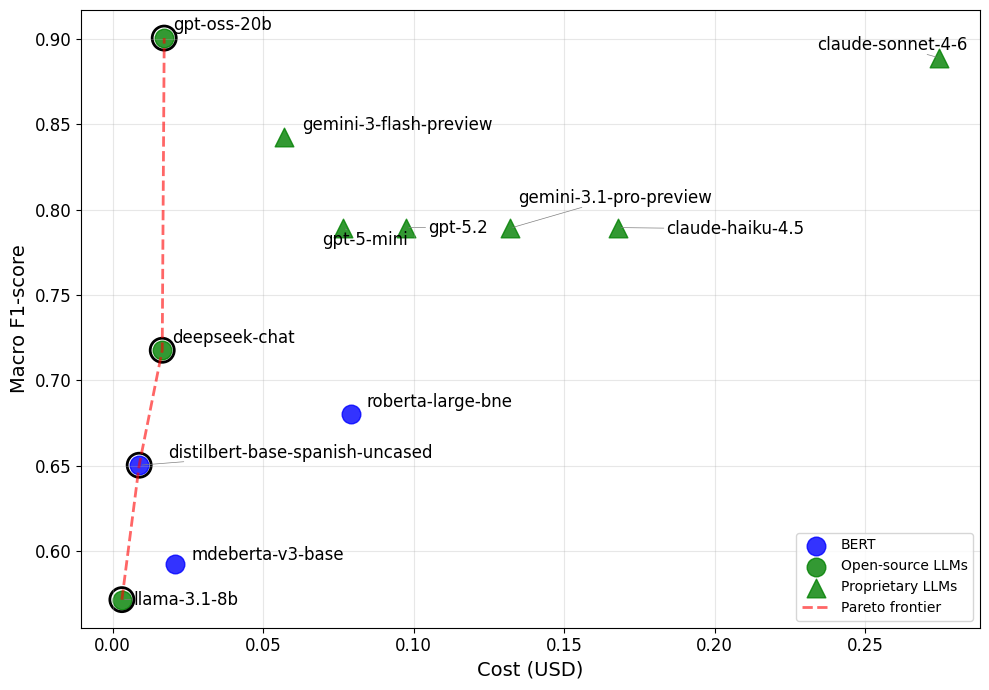

In [ ]:
plot_eficacia_coste(metricas_anx, "anx")

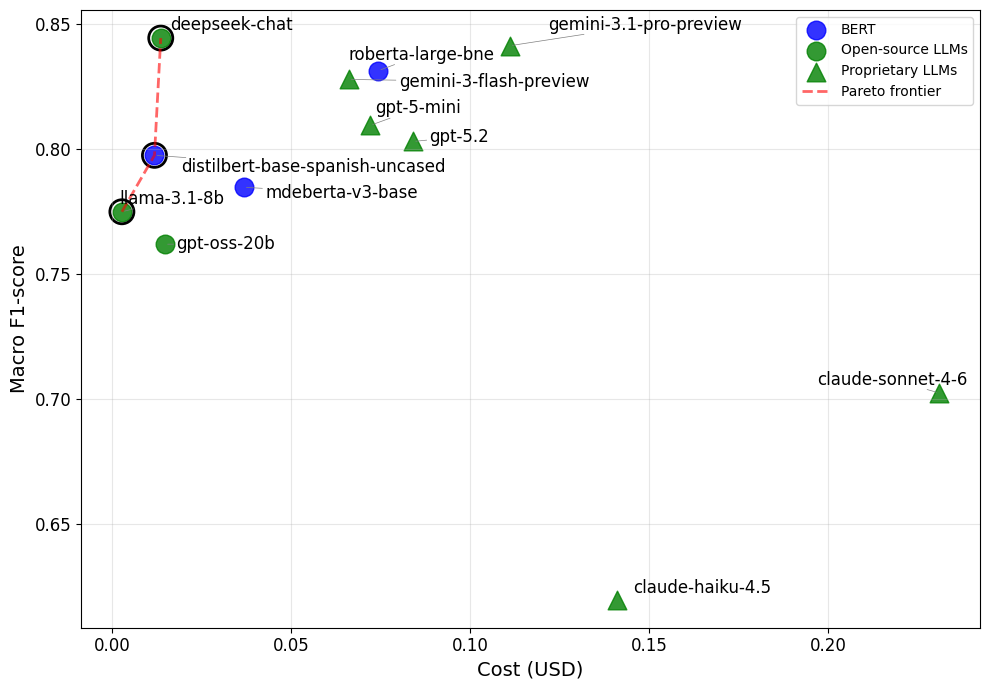

In [ ]:
plot_eficacia_coste(metricas_dep, "dep")

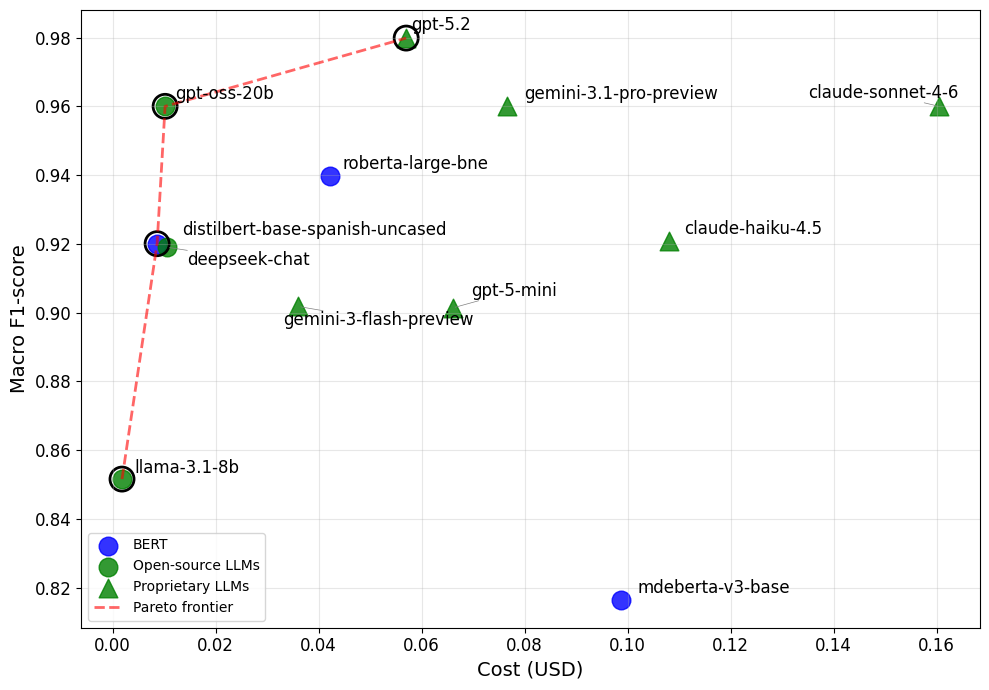

In [ ]:
plot_eficacia_coste(metricas_ed, "ed")

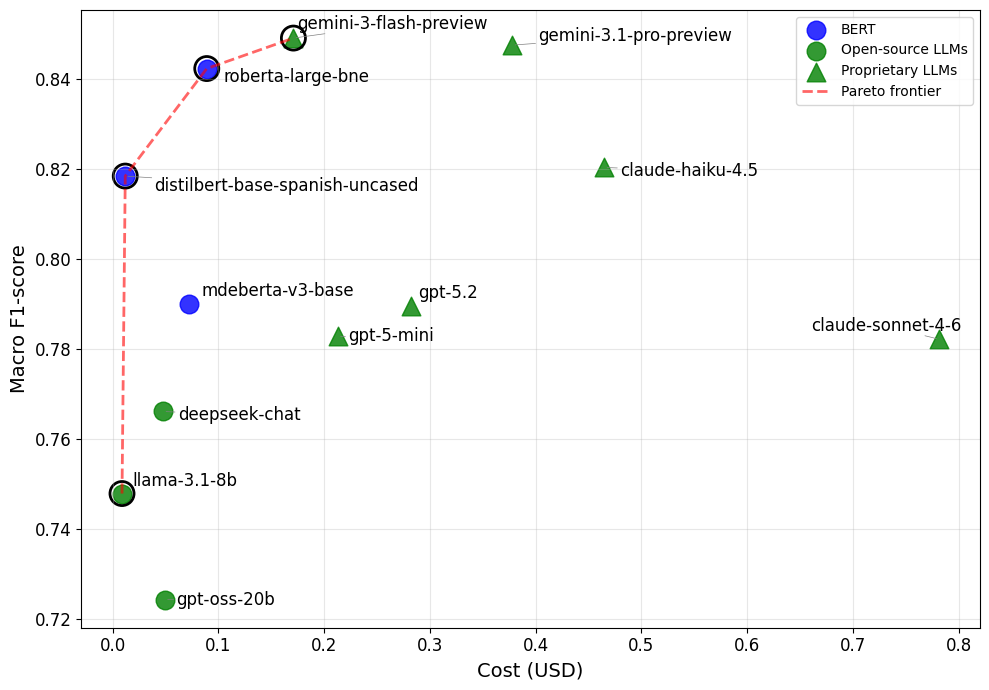

In [ ]:
plot_eficacia_coste(metricas_multi, "multi")